# 02 — Prétraitement et nettoyage des données

Ce notebook transforme `archive/` (données brutes) en `data/` (données propres et découpées), en appliquant les
décisions de `01_EDA.ipynb`. Tout le code vient de `src/data.py` : c'est **exactement** le même pipeline que celui
lancé par `main.py` (`prepare_data()`), ici déroulé étape par étape.

**Étapes**
1. Inventaire
2. Suppression des doublons exacts
3. Reconstruction des séries de coupes
4. Split train / valid / test **par série**
5. Vérification : pourquoi le split par série change tout
6. Export vers `data/`
7. Prétraitement des images (gris, padding, resize) et cache

In [1]:
import os, sys
from pathlib import Path

# Le notebook tourne depuis notebooks/ : on se place à la racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from src import data as D
from src.viz import setup_style, CLASS_COLORS, SPLIT_COLORS, INK_MUTED

setup_style()
OVERWRITE = True   # True = reconstruit data/ (le résultat est identique grâce à la seed)

## 1. Inventaire

In [2]:
df_raw = D.scan_raw()
print(len(df_raw), "images")
df_raw.head()

12446 images


,path,filename,cls,label,num,width,height,view,md5
0,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,Cyst- (1).jpg,Cyst,0,1,705,569,coronal,1b69ba00940b8e23df5f1f62349528fb
1,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,Cyst- (2).jpg,Cyst,0,2,512,512,axial,8ba170c5e054f6ada63ecb1b2d8952af
2,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,Cyst- (3).jpg,Cyst,0,3,512,512,axial,d81ddff68bc8a0f1357cb5f38d5dbc60
3,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,Cyst- (4).jpg,Cyst,0,4,512,512,axial,9cae678b68cd89a4d4c6a1f253858c86
4,archive/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-St...,Cyst- (5).jpg,Cyst,0,5,512,512,axial,df7d10b7920ffaf616ccbc02ce9fc5dc


## 2. Suppression des doublons exacts
On garde la première occurrence de chaque hash md5.

In [3]:
df, removed = D.remove_exact_duplicates(df_raw)
print(f"{len(removed)} doublons supprimés -> {len(df)} images")
pd.DataFrame({"avant": df_raw.cls.value_counts(), "après": df.cls.value_counts()}).reindex(D.CLASSES)

517 doublons supprimés -> 11929 images


,avant,après
cls,,
Cyst,3709,3284
Normal,5077,5002
Stone,1377,1360
Tumor,2283,2283


## 3. Reconstruction des séries de coupes

Dans chaque classe, triée par numéro de fichier, on démarre une **nouvelle série** quand :
- la taille de l'image change (changement d'examen ou de type de coupe), ou
- la distance avec l'image précédente dépasse un seuil (saut d'anatomie = autre examen).

Distance = moyenne de |différence| entre miniatures 32×32 en niveaux de gris dans [0,1].

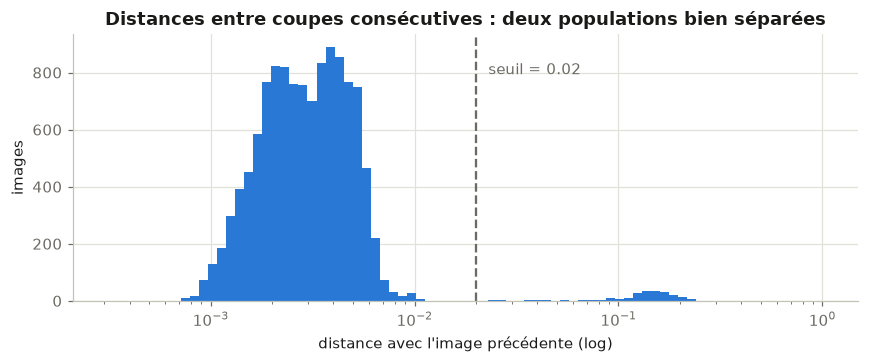

In [4]:
thumbs = D.thumbnails(df["path"])
dist = D.consecutive_distances(df, thumbs)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(dist[~np.isnan(dist)], bins=np.logspace(-3.5, 0, 80), color=CLASS_COLORS["Cyst"])
ax.axvline(D.SERIES_THRESHOLD, color=INK_MUTED, ls="--", lw=1.5)
ax.text(D.SERIES_THRESHOLD * 1.15, ax.get_ylim()[1] * 0.85, f"seuil = {D.SERIES_THRESHOLD}", color=INK_MUTED)
ax.set_xscale("log"); ax.set_xlabel("distance avec l'image précédente (log)"); ax.set_ylabel("images")
ax.set_title("Distances entre coupes consécutives : deux populations bien séparées")
plt.tight_layout(); plt.show()

La distribution est bimodale : la grande majorité des distances est < 0,01 (même série), une petite partie > 0,05 (changement d'examen). Le choix du seuil est peu sensible :

In [5]:
sens = []
for t in [0.01, 0.015, 0.02, 0.03, 0.05]:
    s = D.assign_series(df, dist, t)
    sens.append({"seuil": t, "séries": s.series.nunique(), **s.groupby("cls").series.nunique().to_dict()})
pd.DataFrame(sens).set_index("seuil")

,séries,Cyst,Normal,Stone,Tumor
seuil,,,,,
0.010,234,80,48,78,28
0.015,223,73,48,74,28
0.020,223,73,48,74,28
0.030,216,70,48,70,28
0.050,208,66,48,66,28


In [6]:
df = D.assign_series(df, dist, D.SERIES_THRESHOLD)
sizes = df.groupby("series").size()
print(f"{len(sizes)} séries — taille médiane {sizes.median():.0f} coupes, min {sizes.min()}, max {sizes.max()}")
df.groupby("cls").agg(images=("path", "size"), series=("series", "nunique")).reindex(D.CLASSES)

223 séries — taille médiane 31 coupes, min 1, max 222


,images,series
cls,,
Cyst,3284,73
Normal,5002,48
Stone,1360,74
Tumor,2283,28


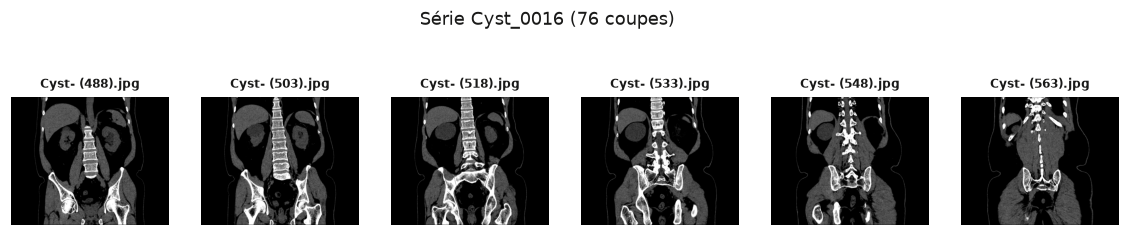

In [7]:
# Une série : début, milieu, fin
s = sizes[sizes > 30].index[3]
g = df[df.series == s]
picks = g.iloc[np.linspace(0, len(g) - 1, 6).astype(int)]
fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
for ax, (_, row) in zip(axes, picks.iterrows()):
    ax.imshow(Image.open(row.path).convert("L"), cmap="gray"); ax.axis("off"); ax.set_title(row.filename, fontsize=8)
plt.suptitle(f"Série {s} ({len(g)} coupes)", y=1.02); plt.show()

**Limite :** ces séries sont une **approximation** des examens patients (aucun ID n'est fourni). Deux séries
peuvent venir du même patient, ce qui laisse une fuite résiduelle possible. Le split par série est tout de même
beaucoup plus honnête qu'un split image par image.

## 4. Split train / valid / test par série

Pour chaque classe : on mélange les séries (seed 42) et on les attribue entières à test (~15 %), puis
valid (~15 %), puis train. Une série n'est **jamais** partagée entre deux splits.

In [8]:
df = D.group_split(df, val_size=0.15, test_size=0.15, seed=42)

assert df.groupby("series")["split"].nunique().max() == 1, "une série est dans plusieurs splits !"
counts = df.groupby(["split", "cls"]).size().unstack().reindex(D.SPLITS)[D.CLASSES]
print("Images par split :")
display(counts.assign(total=counts.sum(axis=1)))
print("Proportion de chaque classe dans chaque split :")
display((counts.div(counts.sum(axis=0), axis=1) * 100).round(1))
print("Nombre de séries :")
display(df.groupby(["split", "cls"]).series.nunique().unstack().reindex(D.SPLITS)[D.CLASSES])

Images par split :


cls,Cyst,Normal,Stone,Tumor,total
split,,,,,
train,2259,3443,938,1526,8166
valid,512,686,197,393,1788
test,513,873,225,364,1975


Proportion de chaque classe dans chaque split :


cls,Cyst,Normal,Stone,Tumor
split,,,,
train,68.8,68.8,69.0,66.8
valid,15.6,13.7,14.5,17.2
test,15.6,17.5,16.5,15.9


Nombre de séries :


cls,Cyst,Normal,Stone,Tumor
split,,,,
train,49,32,41,20
valid,13,7,12,3
test,11,9,21,5


In [9]:
pd.crosstab([df.split, df.cls], df.view).reindex(D.SPLITS, level=0)

view          axial  coronal
split cls                   
train Cyst     1121     1138
      Normal   2543      900
      Stone     568      370
      Tumor     988      538
valid Cyst      292      220
      Normal    304      382
      Stone     108       89
      Tumor      96      297
test  Cyst      467       46
      Normal    427      446
      Stone     180       45
      Tumor     256      108

**À noter :** Tumor ne compte que 28 séries, donc seulement 3 en validation. Les métriques de validation sur
Tumor seront **bruitées**. Pour des comparaisons fines entre modèles, une validation croisée par groupes
(`StratifiedGroupKFold` sur `series`) serait plus fiable.

## 5. Vérification : pourquoi le split par série change tout

Pour chaque image de test, on cherche l'image de train la plus proche. On compare avec ce qu'aurait donné un
split aléatoire image par image (celui du premier baseline).

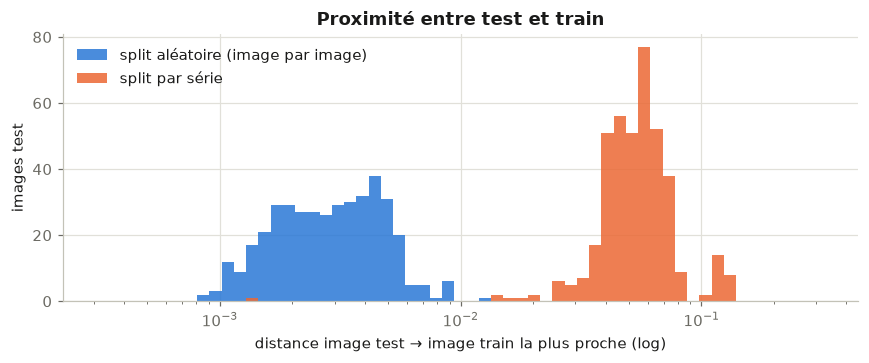

médiane — aléatoire : 0.0029   par série : 0.0547


In [10]:
from sklearn.model_selection import train_test_split

def nearest_train_distance(test_idx, train_idx, n=400, seed=0):
    test_idx = np.random.RandomState(seed).choice(test_idx, n, replace=False)
    Tt, Tr = thumbs[test_idx], thumbs[train_idx]
    return np.array([np.abs(Tr - t).mean(1).min() for t in Tt])

idx = np.arange(len(df))
rand_tr, rand_te = train_test_split(idx, test_size=0.15, stratify=df.label, random_state=42)
d_rand = nearest_train_distance(rand_te, rand_tr)
d_group = nearest_train_distance(idx[df.split == "test"], idx[df.split == "train"])

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(-3.5, -0.5, 60)
ax.hist(d_rand, bins=bins, alpha=0.85, color=SPLIT_COLORS["train"], label="split aléatoire (image par image)")
ax.hist(d_group, bins=bins, alpha=0.85, color=SPLIT_COLORS["valid"], label="split par série")
ax.set_xscale("log"); ax.set_xlabel("distance image test → image train la plus proche (log)"); ax.set_ylabel("images test")
ax.set_title("Proximité entre test et train"); ax.legend()
plt.tight_layout(); plt.show()
print(f"médiane — aléatoire : {np.median(d_rand):.4f}   par série : {np.median(d_group):.4f}")

Avec un split aléatoire, presque chaque image de test a un quasi-double en train : le test mesure de la
**mémorisation**. Le split par série éloigne nettement le test du train. Les scores seront plus bas, mais ils
mesureront la capacité à **généraliser à de nouveaux examens**.

## 6. Export vers `data/`

`data/{train,valid,test}/<classe>/` contient des **hardlinks** vers les fichiers d'`archive/` : aucun octet de plus
sur le disque, et `archive/` n'est jamais modifié. `data/metadata.csv` garde la trace de chaque image
(série, vue, split…).

In [11]:
D.export_splits(df, overwrite=OVERWRITE)
meta = pd.read_csv(D.DATA_DIR / "metadata.csv")
print(len(meta), "lignes dans data/metadata.csv")
for s in D.SPLITS:
    n = sum(1 for _ in (D.DATA_DIR / s).rglob("*.jpg"))
    print(f"data/{s:5s}: {n} images")

11929 lignes dans data/metadata.csv
data/train: 8166 images
data/valid: 1788 images
data/test : 1975 images


## 7. Prétraitement des images

Pour chaque image (`src.data.preprocess_image`) :
1. conversion en **1 canal** (les 3 canaux RGB sont identiques) ;
2. **padding noir** jusqu'au carré, centré : les coupes coronales ne sont pas déformées ;
3. **resize** à `img_size` (128 px pour le baseline).

Au moment de l'entraînement (`src.data.prep`) : passage en float dans [0,1], centrage dans [-1,1], et
**flip horizontal** aléatoire sur le train uniquement (augmentation).

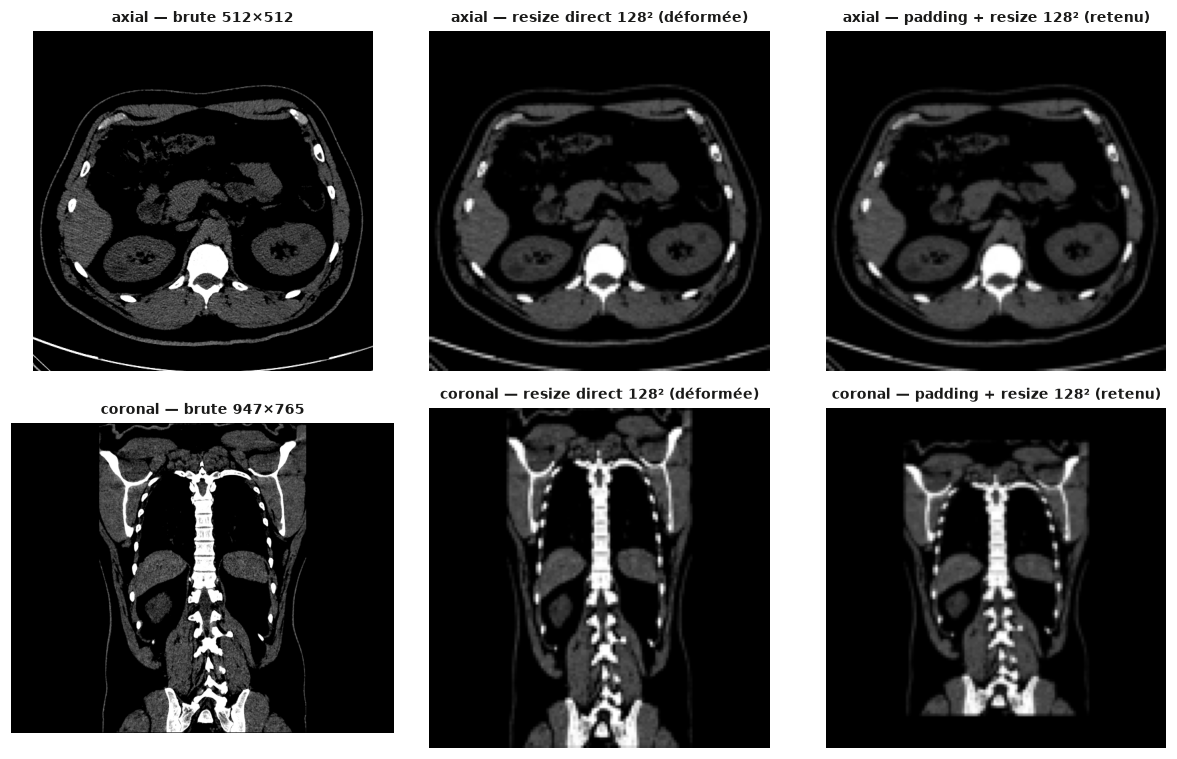

In [12]:
IMG_SIZE = 128
examples = [meta[(meta.view == v) & (meta.split == "train")].iloc[0] for v in ["axial", "coronal"]]
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for r, row in enumerate(examples):
    raw = Image.open(row.path).convert("L")
    squashed = raw.resize((IMG_SIZE, IMG_SIZE))
    padded = D.preprocess_image(row.path, IMG_SIZE)
    for ax, img, title in zip(axes[r], [raw, squashed, padded],
                              [f"brute {raw.size[0]}×{raw.size[1]}", f"resize direct {IMG_SIZE}² (déformée)",
                               f"padding + resize {IMG_SIZE}² (retenu)"]):
        ax.imshow(img, cmap="gray"); ax.set_title(f"{row.view} — {title}", fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

On construit le cache `data/cache/<split>_<taille>.npz` (images prétraitées en uint8), utilisé par `train.py` et `eval.py` :

In [13]:
for s in D.SPLITS:
    X, y = D.load_split(s, IMG_SIZE)
    print(f"{s:5s}: X {X.shape} {X.dtype}  ({X.nbytes / 1e6:.0f} Mo)  — y : {np.bincount(y)}")

train: X (8166, 128, 128) uint8  (134 Mo)  — y : [2259 3443  938 1526]


valid: X (1788, 128, 128) uint8  (29 Mo)  — y : [512 686 197 393]


test : X (1975, 128, 128) uint8  (32 Mo)  — y : [513 873 225 364]


## Résumé

| | |
|---|---|
| Images brutes | 12 446 |
| Doublons exacts retirés | 517 |
| Images retenues | 11 929 |
| Séries reconstituées | 223 |
| Split | par série, stratifié par classe, ~70 / 15 / 15 |
| Image modèle | 1 canal, padding carré, 128×128, normalisée dans [-1, 1] |

Les données sont prêtes : les notebooks de modèles (`03_…`) partent de `data/`.